In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
# ..\data\05001 (Comunidades) Hechos conocidos de infracciones penales relacionadas con cibercriminalidad por grupo penal.csv
df = pd.read_csv("../data/05001 (Comunidades) Hechos conocidos de infracciones penales relacionadas con cibercriminalidad por grupo penal.csv", sep=";", thousands=".")
df

,Comunidades autónomas,Grupo penal,periodo,Total
0,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2025,13753
1,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2024,9773
2,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2023,7367
3,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2022,5578
4,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2021,5342
...,...,...,...,...
2965,DESCONOCIDA,TOTAL grupo penal,2015,0
2966,DESCONOCIDA,TOTAL grupo penal,2014,0
2967,DESCONOCIDA,TOTAL grupo penal,2013,0
2968,DESCONOCIDA,TOTAL grupo penal,2012,0


In [2]:
df["Grupo penal"].unique()

<StringArray>
[          'ACCESO  E INTERCEPTACIÓN ILÍCITA',
                      'AMENAZAS Y COACCIONES',
                            'CONTRA EL HONOR',
 'CONTRA LA PROPIEDAD INDUSTRIAL/INTELECTUAL',
                           'DELITOS SEXUALES',
                  'FALSIFICACIÓN INFORMÁTICA',
                         'FRAUDE INFORMÁTICO',
 'INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA',
                          'TOTAL grupo penal']
Length: 9, dtype: str

In [5]:
# condición de filtrado
df_filtrado = df[
    (df["Comunidades autónomas"] != "TOTAL NACIONAL") & 
    (df["Grupo penal"] != "TOTAL grupo penal")
]

# el índice del valor Total más alto para cada Año
indices_maximos = df_filtrado.groupby("periodo")["Total"].idxmax()

# filas correspondientes a esos índices
df_maximos_por_anio = df_filtrado.loc[indices_maximos]

# resultado ordenado por año
df_maximos_por_anio.sort_values(by="periodo" , ascending=False )

,Comunidades autónomas,Grupo penal,periodo,Total
225,ANDALUCÍA,FRAUDE INFORMÁTICO,2025,77117
1306,CATALUÑA,FRAUDE INFORMÁTICO,2024,72139
1307,CATALUÑA,FRAUDE INFORMÁTICO,2023,73994
1308,CATALUÑA,FRAUDE INFORMÁTICO,2022,61607
1309,CATALUÑA,FRAUDE INFORMÁTICO,2021,47314
1310,CATALUÑA,FRAUDE INFORMÁTICO,2020,46982
1311,CATALUÑA,FRAUDE INFORMÁTICO,2019,40016
1312,CATALUÑA,FRAUDE INFORMÁTICO,2018,36808
1313,CATALUÑA,FRAUDE INFORMÁTICO,2017,26574
1314,CATALUÑA,FRAUDE INFORMÁTICO,2016,18077


# Dataset 1. Evolución de la ciberdelincuencia

In [6]:
# Filtrado para obtener la evolución nacional por tipo de delito
# Seleccionamos únicamente el TOTAL NACIONAL para ver la tendencia
# Excluimos la fila que agrupa la suma de todos los delitos ("TOTAL grupo penal") para no duplicar datos
df_dataset1 = df[
    (df["Comunidades autónomas"] == "TOTAL NACIONAL") & 
    (df["Grupo penal"] != "TOTAL grupo penal")
]
df_dataset1

,Comunidades autónomas,Grupo penal,periodo,Total
0,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2025,13753
1,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2024,9773
2,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2023,7367
3,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2022,5578
4,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,2021,5342
...,...,...,...,...
115,TOTAL NACIONAL,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2015,1193
116,TOTAL NACIONAL,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2014,440
117,TOTAL NACIONAL,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2013,359
118,TOTAL NACIONAL,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,2012,298


In [ ]:
df_dataset1 = df_dataset1[["periodo", "Grupo penal", "Total"]].sort_values(by=["periodo", "Total"], ascending=[False, False])
df_dataset1

,periodo,Grupo penal,Total
90,2025,FRAUDE INFORMÁTICO,429677
75,2025,FALSIFICACIÓN INFORMÁTICA,21690
15,2025,AMENAZAS Y COACCIONES,18194
0,2025,ACCESO E INTERCEPTACIÓN ILÍCITA,13753
60,2025,DELITOS SEXUALES,2031
...,...,...,...
89,2011,FALSIFICACIÓN INFORMÁTICA,1860
14,2011,ACCESO E INTERCEPTACIÓN ILÍCITA,1492
74,2011,DELITOS SEXUALES,755
119,2011,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,228


In [9]:
# Guardar el nuevo Dataset
df_dataset1.to_csv("../data/dataset1_evolucion_ciberdelincuencia.csv", index=False, sep=";")

In [10]:
# Identificar tendencias por Grupo Penal
# qué ciberdelitos son los más comunes acumulando todos los años
df_dataset1.groupby("Grupo penal")["Total"].sum().sort_values(ascending=False)

Grupo penal
FRAUDE INFORMÁTICO                            2794739
AMENAZAS Y COACCIONES                          198477
FALSIFICACIÓN INFORMÁTICA                      109272
ACCESO  E INTERCEPTACIÓN ILÍCITA                69989
CONTRA EL HONOR                                 23831
DELITOS SEXUALES                                21064
INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA      18621
CONTRA LA PROPIEDAD INDUSTRIAL/INTELECTUAL       2437
Name: Total, dtype: int64

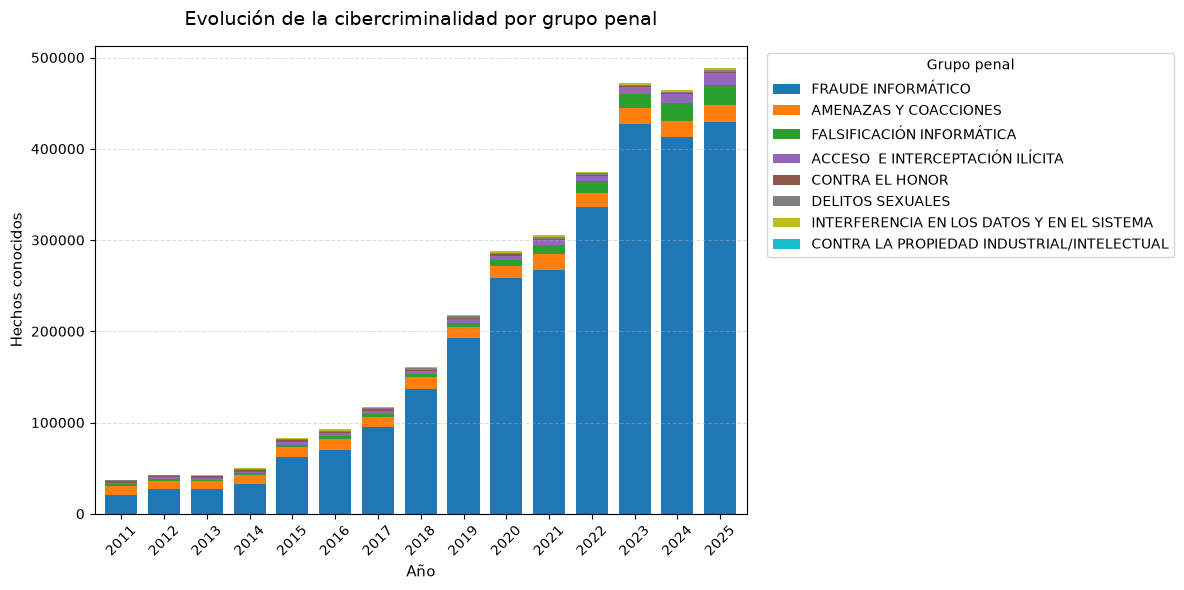

In [18]:
# Pivotar temporalmente para graficar
df_pivot = df_dataset1.pivot(index="periodo", columns="Grupo penal", values="Total").sort_index()

# Ordenar columnas de mayor a menor volumen 
orden_cols = df_pivot.sum().sort_values(ascending=False).index
df_pivot = df_pivot[orden_cols]

ax = df_pivot.plot(kind="bar", stacked=True, figsize=(12, 6), colormap="tab10", width=0.75)
ax.set_title("Evolución de la cibercriminalidad por grupo penal", fontsize=14, pad=15)
ax.set_xlabel("Año", fontsize=11)
ax.set_ylabel("Hechos conocidos", fontsize=11)
ax.legend(title="Grupo penal", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
